In [1]:
NAMES = ['Angela DiAndreth', 'Sergey Dutt', 'Edward Lombo-Becerra']

In [2]:
import jax
import jax.numpy as jnp
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt

In [13]:
from fix_data import get_random_subset, load_and_center_data  

In [47]:
df = load_and_center_data('Pendulum.xlsx')
subset_df = get_random_subset(df, 50)

t_start_orig = subset_df['Time'].iloc[0]
t_end_orig = subset_df['Time'].iloc[-1]

print(f"Subset original time window: {t_start_orig:.1f} s to {t_end_orig:.1f} s")

subset_df['Time'] = subset_df['Time'] - subset_df['Time'].iloc[0]

t_data = np.array(subset_df['Time'].values)
theta_data = np.array(subset_df['Angle'].values)

Subset original time window: 217.1 s to 348.1 s


In [52]:
def fourier_series(t_data, theta_data, max_K=10, tol=1e-3):
    # find peaks in subset
    peaks, _ = signal.find_peaks(theta_data)

    # average period
    t_diff = t_data[peaks[-1]] - t_data[peaks[0]]
    T_avg = t_diff / (len(peaks) - 1)
    # angular frequency
    freq = 2 * np.pi / T_avg

    first_peak = theta_data[peaks[0]]
    last_peak = theta_data[peaks[-1]]

    # decay constant
    Lambda = np.log(first_peak / last_peak) / t_diff
    decay = jnp.exp(-Lambda * t_data)

    # initial conditions 
    prev_mse = float('inf')
    best_a = None
    best_K = 1

    for K in range(1, max_K + 1):
        cols = []
        for k in range(1, K + 1):
            cols.append(decay * jnp.cos(k * freq * t_data))
            cols.append(decay * jnp.sin(k * freq * t_data))

        X = jnp.column_stack(cols)
        Y = theta_data

        # solve for [A_1, B_1, ..., A_K, B_K]
        a = jnp.linalg.solve(X.T @ X, X.T @ Y)

        # model prediction at current K
        f_series = X @ a

        # calculate MSE and check stopping condition
        curr_mse = float(jnp.mean((theta_data - f_series) ** 2))

        if K > 1:
            rel_improvement = (prev_mse - curr_mse) / prev_mse
            if rel_improvement < tol:
                # at less than 1% improvement; stop and keep previous K fit
                break

        # save current best coefficients and update MSE
        best_a = a
        best_K = K
        prev_mse = curr_mse

    # convert optimal coefficients to a static JAX array
    best_a_jnp = jnp.array(best_a)

    # CONTINUOUS FUNCTION THAT JAX.GRAD USES 
    def theta_func(t):
        decay_t = jnp.exp(-Lambda * t)
        summation = 0.0
        idx = 0
        for k in range(1, best_K + 1):
            summation = (
                summation
                + best_a_jnp[idx] * jnp.cos(k * freq * t)
                + best_a_jnp[idx + 1] * jnp.sin(k * freq * t)
            )
            idx += 2
        return decay_t * summation

    return theta_func, best_K

In [53]:
# get the continuous differentiable function and total K's used 
theta_func, final_K = fourier_series(t_data, theta_data)

# first and second derivatives (as functions of t)    
theta_dot_func = jax.grad(theta_func)
theta_ddot_func = jax.grad(theta_dot_func)

# evaluate derivatives at all time points t_data using vmap
theta_dot = jax.vmap(theta_dot_func)(t_data)
theta_ddot = jax.vmap(theta_ddot_func)(t_data)

print(f"Final selected K: {final_K}")

Final selected K: 3


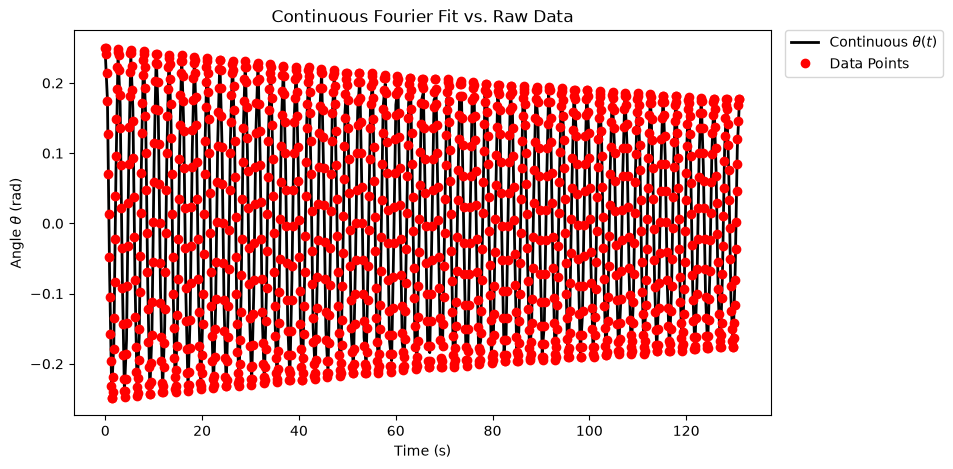

In [54]:
t_plot = jnp.linspace(t_data[0], t_data[-1], 300)
theta_plot = jax.vmap(theta_func)(t_plot)

# plot continuous f-series against discrete data points
plt.figure(figsize=(9, 5), dpi=100)
plt.plot(t_plot, theta_plot, label='Continuous $\\theta(t)$', color='black', linewidth=2)
plt.plot(t_data, theta_data, 'ro', label='Data Points')
plt.xlabel('Time (s)')
plt.ylabel('Angle $\\theta$ (rad)')
plt.title('Continuous Fourier Fit vs. Raw Data')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.show()

In [55]:
# linear regression for the differential equation                                                          
Y = theta_ddot
X = jnp.column_stack([-theta_dot, -jnp.sin(theta_data)])

a = jnp.linalg.solve(X.T @ X, X.T @ Y)
a1 = float(a[0])
a2 = float(a[1])

# model: theta'' + a1*theta' + a2*sin(theta) = 0                                     
# a1 = c / m*L^2, a2 = g/L, g = 9.81                                                 
g = 9.81 # m / s^2                                                                   
L_data = 1.615 # m                                                                   
m_data = 1 # kg                                                                      

L_model = g / a2
L_err = jnp.abs(L_model - L_data) * 100
C_model = a1 * m_data * (L_model**2)

print(f'L_model: {L_model:.3f} m')
print(f'L_model error: {float(L_err):.3f} cm')
print(f'Air-Resistance Coef (C): {C_model:.3f}')

L_model: 1.694 m
L_model error: 7.919 cm
Air-Resistance Coef (C): 0.016
